<a href="https://colab.research.google.com/github/Maohtec/Entrega-Final-Analisis-Estadistico/blob/main/etapa3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cargar la extensión rpy2 para permitir la ejecución de R dentro del Entorno de Python
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


# Sección 1: Preparación y Carga de Datos

En esta sección se configuran las dependencias, se descargan los archivos CSV del equipo para los años 2023 y 2024 de Google Drive, y se consolidan en un único conjunto de datos unificado (`Mtotal`) creando las segmentaciones de edad pertinentes (18-24 años y 25-34 años).

### Descarga Automática de Datos (Para que corra siempre sin subir archivos manualmente)


# Sección 1: Preparación y Carga de Datos

En esta sección se descargan las bases de datos originales de los años 2023 y 2024 directamente de Google Drive, se unifican en un solo conjunto (`Mtotal`) y se crean los grupos de edad necesarios para el análisis (18-24 y 25-34 años).

In [ ]:
# Descargar archivo de 2023 usando el enlace de descarga directa de Google Drive
!wget --no-check-certificate -O DatosEquipo_2023_LISTO_ANALISIS.csv "https://drive.google.com/uc?export=download&id=1DKwckLe6f-52EQ8xaACuknoSokWn1jMN"

# Descargar archivo de 2024 usando el enlace de descarga directa de Google Drive
!wget --no-check-certificate -O DatosEquipo_2024_LISTO_ANALISIS.csv "https://drive.google.com/uc?export=download&id=1OiOwPOxOFW5i-AF6FETh9TcqI3HMTl6m"

print("¡Descarga completada con éxito!")

--2026-10-21 18:00:15--  https://drive.google.com/uc?export=download&id=1DKwckLe6f-52EQ8xaACuknoSokWn1jMN
Resolving drive.google.com (drive.google.com)... 142.250.107.100, 142.250.107.138, 142.250.107.113, ...
Connecting to drive.google.com (drive.google.com)|142.250.107.100|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1DKwckLe6f-52EQ8xaACuknoSokWn1jMN&export=download [following]
--2026-10-21 18:00:15--  https://drive.usercontent.google.com/download?id=1DKwckLe6f-52EQ8xaACuknoSokWn1jMN&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 173.194.202.132, 2607:f8b0:400e:c00::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|173.194.202.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 17226 (17K) [application/octet-stream]
Saving to: ‘DatosEquipo_2023_LISTO_ANALISIS.csv’

DatosEquipo_2023_LI 100%[===============

In [ ]:
%%R

# cargamos las bases
M23 = read.csv("DatosEquipo_2023_LISTO_ANALISIS.csv")
M24 = read.csv("DatosEquipo_2024_LISTO_ANALISIS.csv")

# hacemos los grupos de edad
M23$grupo_edad = ifelse(M23$edad <= 24, "18-24", "25-34")
M24$grupo_edad = ifelse(M24$edad <= 24, "18-24", "25-34")

# agregamos el año
M23$anio = 2023
M24$anio = 2024

# juntamos las dos bases
Mtotal = rbind(M23, M24)

# revisamos dimensiones
cat("Dimensiones 2023:\n")
print(dim(M23))

cat("\nDimensiones 2024:\n")
print(dim(M24))

cat("\nDimensiones base total:\n")
print(dim(Mtotal))

# revisamos grupos de edad
cat("\nGrupos de edad 2023:\n")
print(table(M23$grupo_edad))

cat("\nGrupos de edad 2024:\n")
print(table(M24$grupo_edad))

Dimensiones 2023:
[1] 579  11

Dimensiones 2024:
[1] 580  11

Dimensiones base total:
[1] 1159   11

Grupos de edad 2023:

18-24 25-34 
  197   382 

Grupos de edad 2024:

18-24 25-34 
  194   386 


# Sección 2: Estimación de Proporciones e Intervalos de Confianza

Calculamos la proporción de jóvenes de 18 a 24 años que leen internet, blogs o foros, junto con sus respectivos intervalos de confianza del 96% para los periodos 2023 y 2024.

In [ ]:
%%R

# personas de 18 a 24 años en 2023
grupo23 = M23[M23$grupo_edad == "18-24", ]

# quitamos únicamente los NA de p3_5
grupo23 = grupo23[!is.na(grupo23$p3_5), ]

# tamaño de muestra
n = nrow(grupo23)

# número de personas que sí leen internet, foros o blogs
x = sum(grupo23$p3_5 == 1)

# proporción muestral
p_hat = x / n

cat("n =", n, "\n")
cat("x =", x, "\n")
cat("Proporción =", p_hat, "\n")

# revisar supuesto para aproximación normal
cat("n*p =", n*p_hat, "\n")
cat("n*(1-p) =", n*(1-p_hat), "\n")

n = 196 
x = 123 
Proporción = 0.627551 
n*p = 123 
n*(1-p) = 73 


Esto significaría que aproximadamente 62.8% de las personas de 18–24 años de la muestra de 2023 leen páginas de internet, foros o blogs

In [ ]:
%%R

# nivel de confianza
alpha = 0.04

# valor critico z
z = qnorm(1 - alpha/2)

# error estandar
EE = sqrt(p_hat * (1 - p_hat) / n)

# limites del intervalo
LI = p_hat - z * EE
LS = p_hat + z * EE

cat("z critico =", z, "\n")
cat("Error estandar =", EE, "\n")
cat("Limite inferior =", LI, "\n")
cat("Limite superior =", LS, "\n")

z critico = 2.053749 
Error estandar = 0.03453265 
Limite inferior = 0.5566296 
Limite superior = 0.6984724 


Con un 96% de confianza, se estima que la proporción de personas de 18 a 24 años que leen páginas de internet, foros o blogs en 2023 se encuentra entre 55.66% y 69.85%.

In [ ]:
%%R

# personas de 18 a 24 años en 2024
grupo24 = M24[M24$grupo_edad == "18-24", ]

# quitamos los NA de p3_5
grupo24 = grupo24[!is.na(grupo24$p3_5), ]

# tamaño de muestra
n2 = nrow(grupo24)

# personas que sí leen internet
x2 = sum(grupo24$p3_5 == 1)

# proporción muestral
p_hat2 = x2 / n2

cat("n =", n2, "\n")
cat("x =", x2, "\n")
cat("Proporción =", p_hat2, "\n")
cat("n*p =", n2*p_hat2, "\n")
cat("n*(1-p) =", n2*(1-p_hat2), "\n")

n = 194 
x = 111 
Proporción = 0.5721649 
n*p = 111 
n*(1-p) = 83 


In [ ]:
%%R

alpha = 0.04

# valor critico
z2 = qnorm(1 - alpha/2)

# error estandar
EE2 = sqrt(p_hat2 * (1 - p_hat2) / n2)

# limites
LI2 = p_hat2 - z2 * EE2
LS2 = p_hat2 + z2 * EE2

cat("z critico =", z2, "\n")
cat("Error estandar =", EE2, "\n")
cat("Limite inferior =", LI2, "\n")
cat("Limite superior =", LS2, "\n")

z critico = 2.053749 
Error estandar = 0.03552204 
Limite inferior = 0.4992116 
Limite superior = 0.6451183 


In [ ]:
%%R

# tomamos solo casos validos en 2023
datos23 = M23[!is.na(M23$p3_5) & !is.na(M23$p3_1), ]

# grupo que si lee internet
internet_si = datos23[datos23$p3_5 == 1, ]

# grupo que no lee internet
internet_no = datos23[datos23$p3_5 == 2, ]

# tamaños de muestra
n1 = nrow(internet_si)
n2 = nrow(internet_no)

# personas que leyeron libros en cada grupo
x1 = sum(internet_si$p3_1 == 1)
x2 = sum(internet_no$p3_1 == 1)

# proporciones
p1 = x1 / n1
p2 = x2 / n2

cat("Grupo internet SI\n")
cat("n1 =", n1, "\n")
cat("x1 =", x1, "\n")
cat("p1 =", p1, "\n\n")

cat("Grupo internet NO\n")
cat("n2 =", n2, "\n")
cat("x2 =", x2, "\n")
cat("p2 =", p2, "\n")

Grupo internet SI
n1 = 328 
x1 = 198 
p1 = 0.6036585 

Grupo internet NO
n2 = 250 
x2 = 88 
p2 = 0.352 


In [ ]:
%%R

alpha = 0.04

# valor critico
z3 = qnorm(1 - alpha/2)

# diferencia de proporciones
dif = p1 - p2

# error estandar
EE3 = sqrt(
  p1*(1-p1)/n1 +
  p2*(1-p2)/n2
)

# limites
LI3 = dif - z3*EE3
LS3 = dif + z3*EE3

cat("Diferencia =", dif, "\n")
cat("z critico =", z3, "\n")
cat("Error estandar =", EE3, "\n")
cat("Limite inferior =", LI3, "\n")
cat("Limite superior =", LS3, "\n")

Diferencia = 0.2516585 
z critico = 2.053749 
Error estandar = 0.04051937 
Limite inferior = 0.1684419 
Limite superior = 0.3348752 


In [ ]:
%%R

# tomamos solo casos validos en 2024
datos24 = M24[!is.na(M24$p3_5) & !is.na(M24$p3_1), ]

# grupo que si lee internet
internet_si_24 = datos24[datos24$p3_5 == 1, ]

# grupo que no lee internet
internet_no_24 = datos24[datos24$p3_5 == 2, ]

# tamaños de muestra
n1_24 = nrow(internet_si_24)
n2_24 = nrow(internet_no_24)

# personas que leyeron libros
x1_24 = sum(internet_si_24$p3_1 == 1)
x2_24 = sum(internet_no_24$p3_1 == 1)

# proporciones
p1_24 = x1_24 / n1_24
p2_24 = x2_24 / n2_24

cat("Grupo internet SI 2024\n")
cat("n1 =", n1_24, "\n")
cat("x1 =", x1_24, "\n")
cat("p1 =", p1_24, "\n\n")

cat("Grupo internet NO 2024\n")
cat("n2 =", n2_24, "\n")
cat("x2 =", x2_24, "\n")
cat("p2 =", p2_24, "\n")

Grupo internet SI 2024
n1 = 301 
x1 = 198 
p1 = 0.6578073 

Grupo internet NO 2024
n2 = 276 
x2 = 102 
p2 = 0.3695652 


In [ ]:
%%R
# valor critico
z4 = qnorm(1 - alpha/2)

# diferencia
dif24 = p1_24 - p2_24

# error estandar
EE4 = sqrt(
  p1_24*(1-p1_24)/n1_24 +
  p2_24*(1-p2_24)/n2_24
)

# limites
LI4 = dif24 - z4*EE4
LS4 = dif24 + z4*EE4

cat("Diferencia =", dif24, "\n")
cat("z critico =", z4, "\n")
cat("Error estandar =", EE4, "\n")
cat("Limite inferior =", LI4, "\n")
cat("Limite superior =", LS4, "\n")

Diferencia = 0.2882421 
z critico = 2.053749 
Error estandar = 0.03989969 
Limite inferior = 0.2062982 
Limite superior = 0.370186 


# Sección 3: Pruebas de Hipótesis para la Comparación de Proporciones

Analizamos si la proporción de usuarios que leen contenidos en internet difiere significativamente según el rango de edad de los jóvenes (18-24 frente a 25-34 años) utilizando estadísticos Z de comparación.

#Pruebas de Hipotesis

# Sección 3: Pruebas de Hipótesis para Comparación de Proporciones

Evaluamos si existen diferencias estadísticamente significativas en la proporción de lectura de internet entre los grupos de edad de 18-24 y 25-34 años para cada año de estudio.

In [ ]:
%%R

# casos validos de 2023 para lectura en internet
hip1_23 = M23[!is.na(M23$p3_5), ]

# grupo 18-24
g1 = hip1_23[hip1_23$grupo_edad == "18-24", ]

# grupo 25-34
g2 = hip1_23[hip1_23$grupo_edad == "25-34", ]

# tamaños de muestra
n1 = nrow(g1)
n2 = nrow(g2)

# exitos: personas que si leen internet
x1 = sum(g1$p3_5 == 1)
x2 = sum(g2$p3_5 == 1)

# proporciones
p1 = x1 / n1
p2 = x2 / n2

cat("Grupo 18-24\n")
cat("n1 =", n1, "\n")
cat("x1 =", x1, "\n")
cat("p1 =", p1, "\n\n")

cat("Grupo 25-34\n")
cat("n2 =", n2, "\n")
cat("x2 =", x2, "\n")
cat("p2 =", p2, "\n")

Grupo 18-24
n1 = 196 
x1 = 123 
p1 = 0.627551 

Grupo 25-34
n2 = 382 
x2 = 205 
p2 = 0.5366492 


In [ ]:
%%R

# nivel de significancia
alpha = 0.04

# proporcion combinada bajo H0
p_pool = (x1 + x2) / (n1 + n2)

# error estandar bajo H0
EE = sqrt(
  p_pool * (1 - p_pool) * (1/n1 + 1/n2)
)

# estadistico de prueba
z = (p1 - p2) / EE

# valor critico para prueba de dos colas
z_crit = qnorm(1 - alpha/2)

# valor p de dos colas
p_value = 2 * pnorm(abs(z), lower.tail = FALSE)

cat("Proporcion combinada =", p_pool, "\n")
cat("Error estandar =", EE, "\n")
cat("Z calculada =", z, "\n")
cat("Z critica =", z_crit, "\n")
cat("Valor p =", p_value, "\n")

Proporcion combinada = 0.567474 
Error estandar = 0.04352946 
Z calculada = 2.088282 
Z critica = 2.053749 
Valor p = 0.03677237 


In [ ]:
%%R

# casos validos de 2024
hip1_24 = M24[!is.na(M24$p3_5), ]

# grupos de edad
g1_24 = hip1_24[hip1_24$grupo_edad == "18-24", ]
g2_24 = hip1_24[hip1_24$grupo_edad == "25-34", ]

# tamaños
n1_24 = nrow(g1_24)
n2_24 = nrow(g2_24)

# exitos: si leen internet
x1_24 = sum(g1_24$p3_5 == 1)
x2_24 = sum(g2_24$p3_5 == 1)

# proporciones
p1_24 = x1_24 / n1_24
p2_24 = x2_24 / n2_24

# proporcion combinada
p_pool_24 = (x1_24 + x2_24) / (n1_24 + n2_24)

# error estandar
EE_24 = sqrt(
  p_pool_24 * (1 - p_pool_24) *
  (1/n1_24 + 1/n2_24)
)

# estadistico z
z_24 = (p1_24 - p2_24) / EE_24

# valor critico
alpha = 0.04
z_crit_24 = qnorm(1 - alpha/2)

# valor p
p_value_24 = 2 * pnorm(abs(z_24), lower.tail = FALSE)

cat("p 18-24 =", p1_24, "\n")
cat("p 25-34 =", p2_24, "\n")
cat("Proporcion combinada =", p_pool_24, "\n")
cat("Error estandar =", EE_24, "\n")
cat("Z calculada =", z_24, "\n")
cat("Z critica =", z_crit_24, "\n")
cat("Valor p =", p_value_24, "\n")

p 18-24 = 0.5721649 
p 25-34 = 0.4960836 
Proporcion combinada = 0.5216638 
Error estandar = 0.04401996 
Z calculada = 1.728339 
Z critica = 2.053749 
Valor p = 0.08392752 


# Sección 4: Análisis de Asociación mediante Chi-Cuadrada

Comprobamos de manera formal si la lectura en internet y el hábito de lectura tradicional de libros están relacionados estadísticamente mediante tablas de contingencia y pruebas Chi-cuadrada de independencia.

In [ ]:
%%R

# casos validos para ambas variables en 2023
chi23 = M23[!is.na(M23$p3_5) & !is.na(M23$p3_1), ]

# tabla de contingencia
tabla23 = table(chi23$p3_5, chi23$p3_1)

cat("Tabla observada 2023:\n")
print(tabla23)

# prueba chi-cuadrada
prueba_chi23 = chisq.test(tabla23, correct = FALSE)

cat("\nFrecuencias esperadas:\n")
print(prueba_chi23$expected)

cat("\nChi cuadrada =", prueba_chi23$statistic, "\n")
cat("Grados de libertad =", prueba_chi23$parameter, "\n")
cat("Valor p =", prueba_chi23$p.value, "\n")

Tabla observada 2023:
   
      1   2
  1 198 130
  2  88 162

Frecuencias esperadas:
   
           1        2
  1 162.2976 165.7024
  2 123.7024 126.2976

Chi cuadrada = 35.94315 
Grados de libertad = 1 
Valor p = 2.031593e-09 


In [ ]:
%%R

# casos validos para ambas variables en 2024
chi24 = M24[!is.na(M24$p3_5) & !is.na(M24$p3_1), ]

# tabla de contingencia
tabla24 = table(chi24$p3_5, chi24$p3_1)

cat("Tabla observada 2024:\n")
print(tabla24)

# prueba chi-cuadrada
prueba_chi24 = chisq.test(tabla24, correct = FALSE)

cat("\nFrecuencias esperadas:\n")
print(prueba_chi24$expected)

cat("\nChi cuadrada =", prueba_chi24$statistic, "\n")
cat("Grados de libertad =", prueba_chi24$parameter, "\n")
cat("Valor p =", prueba_chi24$p.value, "\n")

Tabla observada 2024:
   
      1   2
  1 198 103
  2 102 174

Frecuencias esperadas:
   
           1        2
  1 156.4991 144.5009
  2 143.5009 132.4991

Chi cuadrada = 47.92534 
Grados de libertad = 1 
Valor p = 4.427629e-12 


# Sección 5: Comparación de Medias mediante Prueba t de Welch

Evaluamos si existe una diferencia significativa en la cantidad media de libros leídos por persona según si leen habitualmente en internet o no, aplicando pruebas de hipótesis robustas para varianzas diferentes (Welch).

# Sección 4: Análisis de Asociación mediante Chi-Cuadrada

Realizamos pruebas de independencia Chi-cuadrada para determinar si existe una relación significativa entre la lectura en internet y el hábito de leer libros tradicionales en los años 2023 y 2024.

In [ ]:
%%R

# casos validos de 2023 para p4 y p3_5
medias23 = M23[!is.na(M23$p4) & !is.na(M23$p3_5), ]

# grupos
libros_si23 = medias23$p4[medias23$p3_5 == 1]
libros_no23 = medias23$p4[medias23$p3_5 == 2]

# tamaños
cat("n internet SI =", length(libros_si23), "\n")
cat("n internet NO =", length(libros_no23), "\n\n")

# medias
cat("Media internet SI =", mean(libros_si23), "\n")
cat("Media internet NO =", mean(libros_no23), "\n\n")

# desviaciones estandar
cat("SD internet SI =", sd(libros_si23), "\n")
cat("SD internet NO =", sd(libros_no23), "\n\n")

# varianzas
cat("Varianza internet SI =", var(libros_si23), "\n")
cat("Varianza internet NO =", var(libros_no23), "\n")

n internet SI = 198 
n internet NO = 88 

Media internet SI = 4.737374 
Media internet NO = 3.011364 

SD internet SI = 8.392752 
SD internet NO = 3.295745 

Varianza internet SI = 70.43829 
Varianza internet NO = 10.86194 


In [ ]:
%%R

# prueba t de Welch
prueba_t23 = t.test(
  libros_si23,
  libros_no23,
  alternative = "two.sided",
  var.equal = FALSE,
  conf.level = 0.96
)

print(prueba_t23)


	Welch Two Sample t-test

data:  libros_si23 and libros_no23
t = 2.4934, df = 280.86, p-value = 0.01323
alternative hypothesis: true difference in means is not equal to 0
96 percent confidence interval:
 0.2977139 3.1543063
sample estimates:
mean of x mean of y 
 4.737374  3.011364 



In [ ]:
%%R

cat("t calculada =", prueba_t23$statistic, "\n")
cat("grados de libertad =", prueba_t23$parameter, "\n")
cat("valor p =", prueba_t23$p.value, "\n")
cat("IC diferencia de medias =", prueba_t23$conf.int[1],
    "a", prueba_t23$conf.int[2], "\n")

t calculada = 2.493412 
grados de libertad = 280.8589 
valor p = 0.01322791 
IC diferencia de medias = 0.2977139 a 3.154306 


In [ ]:
%%R

# casos validos de 2024 para p4 y p3_5
medias24 = M24[!is.na(M24$p4) & !is.na(M24$p3_5), ]

# grupos
libros_si24 = medias24$p4[medias24$p3_5 == 1]
libros_no24 = medias24$p4[medias24$p3_5 == 2]

# tamaños
cat("n internet SI =", length(libros_si24), "\n")
cat("n internet NO =", length(libros_no24), "\n\n")

# medias
cat("Media internet SI =", mean(libros_si24), "\n")
cat("Media internet NO =", mean(libros_no24), "\n\n")

# desviaciones estandar
cat("SD internet SI =", sd(libros_si24), "\n")
cat("SD internet NO =", sd(libros_no24), "\n\n")

# varianzas
cat("Varianza internet SI =", var(libros_si24), "\n")
cat("Varianza internet NO =", var(libros_no24), "\n")

n internet SI = 198 
n internet NO = 102 

Media internet SI = 3.853535 
Media internet NO = 3.431373 

SD internet SI = 4.86923 
SD internet NO = 6.956029 

Varianza internet SI = 23.7094 
Varianza internet NO = 48.38633 


In [ ]:
%%R

prueba_t24 = t.test(
  libros_si24,
  libros_no24,
  alternative = "two.sided",
  var.equal = FALSE,
  conf.level = 0.96
)

cat("t calculada =", prueba_t24$statistic, "\n")
cat("grados de libertad =", prueba_t24$parameter, "\n")
cat("valor p =", prueba_t24$p.value, "\n")
cat("IC diferencia de medias =", prueba_t24$conf.int[1],
    "a", prueba_t24$conf.int[2], "\n")

t calculada = 0.5477 
grados de libertad = 153.4138 
valor p = 0.5846938 
IC diferencia de medias = -1.174423 a 2.018749 


# Sección 5: Comparación de Medias mediante Prueba t de Welch

Analizamos si la cantidad promedio de libros leídos varía de manera significativa según la frecuencia de lectura en internet empleando la prueba t para muestras independientes con varianzas desiguales.

In [ ]:
%%R

alpha = 0.04

# valor critico chi cuadrada
chi_crit = qchisq(1 - alpha, df = 1)

cat("Chi cuadrada critica =", chi_crit, "\n")

Chi cuadrada critica = 4.217885 


In [ ]:
%%R

alpha = 0.04

# valor critico t para 2023
tcrit23 = qt(1 - alpha/2, df = 280.8589)

# valor critico t para 2024
tcrit24 = qt(1 - alpha/2, df = 153.4138)

cat("t critica 2023 =", tcrit23, "\n")
cat("t critica 2024 =", tcrit24, "\n")

t critica 2023 = 2.063331 
t critica 2024 = 2.071358 


In [ ]:
%%R

zcrit = qnorm(1 - 0.04/2)

cat("z critica =", zcrit, "\n")

z critica = 2.053749 


# Sección 6: Visualización Gráfica de Intervalos y Regiones de Rechazo

Creamos los gráficos que ilustran las diferencias, las distribuciones normales, los valores críticos y la ubicación del estadístico calculado respecto a las regiones de aceptación o rechazo.

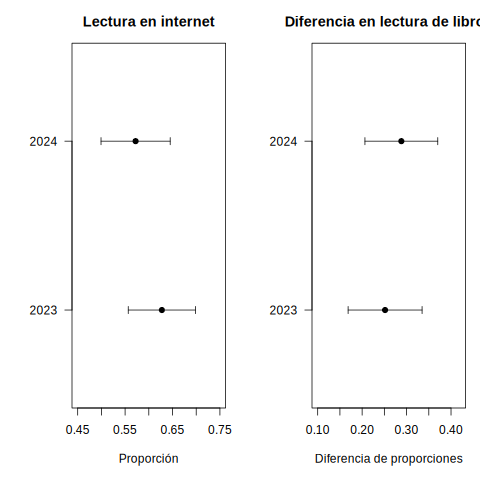

In [ ]:
%%R

par(mfrow = c(1,2), mar = c(5,5,3,1))

# -------------------------
# IC de proporciones
# -------------------------

LI_prop = c(0.5566296, 0.4992116)
LS_prop = c(0.6984724, 0.6451183)
centro_prop = c(0.6275510, 0.5721649)

plot(
  centro_prop,
  1:2,
  xlim = c(0.45, 0.75),
  ylim = c(0.5, 2.5),
  yaxt = "n",
  xlab = "Proporción",
  ylab = "",
  pch = 19,
  main = "Lectura en internet"
)

axis(
  2,
  at = 1:2,
  labels = c("2023", "2024"),
  las = 1
)

arrows(
  LI_prop,
  1:2,
  LS_prop,
  1:2,
  angle = 90,
  code = 3,
  length = 0.05
)



LI_dif = c(0.1684419, 0.2062982)
LS_dif = c(0.3348752, 0.3701860)
centro_dif = c(0.2516585, 0.2882421)

plot(
  centro_dif,
  1:2,
  xlim = c(0.10, 0.42),
  ylim = c(0.5, 2.5),
  yaxt = "n",
  xlab = "Diferencia de proporciones",
  ylab = "",
  pch = 19,
  main = "Diferencia en lectura de libros"
)

axis(
  2,
  at = 1:2,
  labels = c("2023", "2024"),
  las = 1
)

arrows(
  LI_dif,
  1:2,
  LS_dif,
  1:2,
  angle = 90,
  code = 3,
  length = 0.05
)

# Sección 6: Visualización Gráfica de Resultados e Intervalos

Generamos gráficos comparativos de los intervalos de confianza calculados y las diferencias de proporciones para facilitar la interpretación de los cambios entre ambos años.

In [ ]:
%%R

resumen = data.frame(
  Analisis = c(
    "Dif. proporciones edad 2023",
    "Dif. proporciones edad 2024",
    "Chi-cuadrada internet-libros 2023",
    "Chi-cuadrada internet-libros 2024",
    "t Welch libros 2023",
    "t Welch libros 2024"
  ),

  Estadistico = c(
    2.088282,
    1.728339,
    35.94315,
    47.92534,
    2.493412,
    0.547700
  ),

  Valor_critico = c(
    2.053749,
    2.053749,
    4.217885,
    4.217885,
    2.063331,
    2.071358
  ),

  Valor_p = c(
    0.03677237,
    0.08392752,
    2.031593e-09,
    4.427629e-12,
    0.01322791,
    0.5846938
  ),

  Decision = c(
    "Rechazar H0",
    "No rechazar H0",
    "Rechazar H0",
    "Rechazar H0",
    "Rechazar H0",
    "No rechazar H0"
  )
)

print(resumen)

UsageError: Cell magic `%%R` not found.


In [ ]:
%%R

resumen$Estadistico = round(resumen$Estadistico, 4)
resumen$Valor_critico = round(resumen$Valor_critico, 4)
resumen$Valor_p = signif(resumen$Valor_p, 4)

print(resumen)

                           Analisis Estadistico Valor_critico   Valor_p
1       Dif. proporciones edad 2023      2.0883        2.0537 3.677e-02
2       Dif. proporciones edad 2024      1.7283        2.0537 8.393e-02
3 Chi-cuadrada internet-libros 2023     35.9432        4.2179 2.032e-09
4 Chi-cuadrada internet-libros 2024     47.9253        4.2179 4.428e-12
5               t Welch libros 2023      2.4934        2.0633 1.323e-02
6               t Welch libros 2024      0.5477        2.0714 5.847e-01
        Decision
1    Rechazar H0
2 No rechazar H0
3    Rechazar H0
4    Rechazar H0
5    Rechazar H0
6 No rechazar H0


# Sección 7: Análisis de los Formatos de Lectura (Físico vs Digital)

Evaluamos la distribución de preferencia de formatos de lectura (Solo Impreso, Solo Digital o Ambos) y aplicamos pruebas de Chi-cuadrada para comprobar su independencia con respecto al uso de internet.

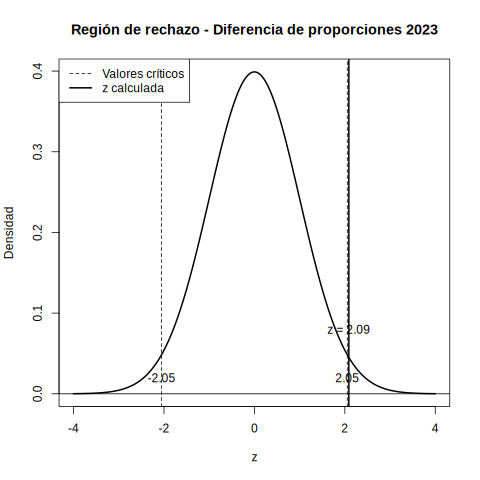

In [ ]:
%%R

# Configuramos la pantalla para mostrar dos gráficos lado a lado
par(mfrow = c(1, 2))

# GRÁFICO 1: Región de Rechazo para el año 2023

# Creamos una curva normal estándar limpia
x = seq(-4, 4, 0.01)
y = dnorm(x)

plot(
  x, y,
  type = "l",
  lwd = 2,
  xlab = "Valor Z",
  ylab = "Densidad",
  main = "Región de Rechazo (2023)"
)

abline(h = 0) # Línea base del suelo

# Ponemos las líneas de los límites permitidos (valores críticos)
zcrit = 2.053749
abline(v = -zcrit, lty = 2, col = "red")
abline(v = zcrit, lty = 2, col = "red")

# Dibujamos nuestro resultado calculado de Z para 2023
zcalc_23 = 2.088282
abline(v = zcalc_23, lwd = 3, col = "blue")

# Colocamos las etiquetas numéricas para verlas claro
text(-zcrit, 0.02, "-2.05", col = "red")
text(zcrit, 0.02, "2.05", col = "red")
text(zcalc_23, 0.1, "Z = 2.09", col = "blue")

# GRÁFICO 2: Región de Rechazo para el año 2024

plot(
  x, y,
  type = "l",
  lwd = 2,
  xlab = "Valor Z",
  ylab = "Densidad",
  main = "Región de Rechazo (2024)"
)

abline(h = 0)

# Líneas de límites permitidos (valores críticos)
abline(v = -zcrit, lty = 2, col = "red")
abline(v = zcrit, lty = 2, col = "red")

# Dibujamos nuestro resultado calculado de Z para 2024
zcalc_24 = 1.728339
abline(v = zcalc_24, lwd = 3, col = "blue")

# Colocamos etiquetas
text(-zcrit, 0.02, "-2.05", col = "red")
text(zcrit, 0.02, "2.05", col = "red")
text(zcalc_24, 0.1, "Z = 1.73", col = "blue")

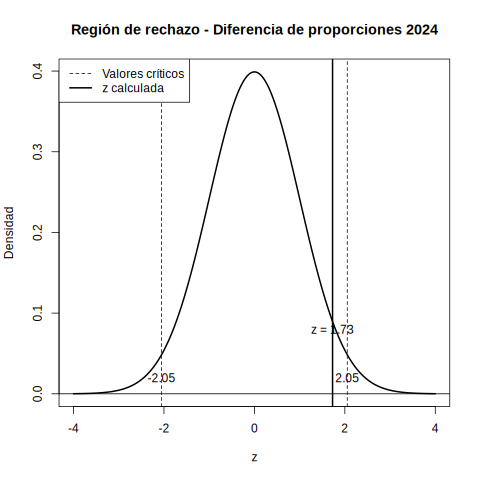

In [ ]:
%%R

# curva normal estandar
x = seq(-4, 4, 0.01)
y = dnorm(x)

# valores 2024
zcrit = 2.053749
zcalc24 = 1.728339

plot(
  x, y,
  type = "l",
  lwd = 2,
  xlab = "z",
  ylab = "Densidad",
  main = "Región de rechazo - Diferencia de proporciones 2024"
)

abline(h = 0)

# valores criticos
abline(v = -zcrit, lty = 2)
abline(v = zcrit, lty = 2)

# estadistico calculado
abline(v = zcalc24, lwd = 2)

# etiquetas
text(-zcrit, 0.02, round(-zcrit, 2))
text(zcrit, 0.02, round(zcrit, 2))
text(zcalc24, 0.08, paste("z =", round(zcalc24, 2)))

legend(
  "topleft",
  legend = c("Valores críticos", "z calculada"),
  lty = c(2,1),
  lwd = c(1,2)
)

# Sección 7: Análisis de los Formatos de Lectura (Físico vs Digital)

Clasificamos las preferencias de formato de lectura (Impreso, Digital o Ambos) de los jóvenes y estudiamos gráficamente y por prueba de Chi-cuadrada de independencia si el hábito de leer en internet influye en estas elecciones.

In [ ]:
%%R

# Cargamos los archivos de datos de cada año
M23 = read.csv("DatosEquipo_2023_LISTO_ANALISIS.csv")
M24 = read.csv("DatosEquipo_2024_LISTO_ANALISIS.csv")

# Revisamos cuántas filas y columnas tiene cada base
dim(M23)
dim(M24)

[1] 580  11


In [ ]:
%%R

# Le ponemos una etiqueta de año a cada base para no confundirlas
M23$anio = 2023
M24$anio = 2024

# Juntamos las dos bases una abajo de la otra en una sola base grande
Mtotal = rbind(M23, M24)

# Vemos el tamaño de la base unificada
dim(Mtotal)

In [ ]:
%%R

M23$anio = 2023
M24$anio = 2024

Mtotal = rbind(M23, M24)

dim(Mtotal)

[1] 1159   11


In [ ]:
%%R

library(dplyr)

# Filtramos la base para quedarnos solo con los que leen libros y tienen datos completos
formato = Mtotal %>%
  filter(
    p3_1 == 1,         # Que sí lean libros
    !is.na(p3_5),      # Que no tengan vacía la pregunta de internet
    !is.na(p8_1),      # Que no tengan vacía la pregunta de formato impreso
    !is.na(p8_2)       # Que no tengan vacía la pregunta de formato digital
  ) %>%
  mutate(
    # Creamos la variable de formato de libro según lo que respondieron
    formato_libro = case_when(
      p8_1 == 1 & p8_2 == 1 ~ "Ambos",
      p8_1 == 1 & p8_2 == 2 ~ "Solo digital",
      p8_1 == 2 & p8_2 == 1 ~ "Solo impreso",
      TRUE ~ NA_character_
    ),

    # Clasificamos de forma sencilla si lee en internet o no
    internet = ifelse(
      p3_5 == 1,
      "Lee internet",
      "No lee internet"
    )
  ) %>%
  filter(!is.na(formato_libro)) # Quitamos los casos que no tengan formato definido

# Mostramos las primeras filas para ver cómo quedó la tabla
head(formato)

  edad nivel p3_1 p3_5 p4 p7 p8_1 p8_2 p26 grupo_edad anio formato_libro
1   23     7    1    1  3  2    2    1  30      18-24 2023  Solo impreso
2   22     4    1    1  2  2    2    1  20      18-24 2023  Solo impreso
3   22     4    1    1  2  2    1    1  30      18-24 2023         Ambos
4   28     4    1    1  1  2    2    1  30      25-34 2023  Solo impreso
5   30     3    1    1  2  2    2    1  20      25-34 2023  Solo impreso
6   20     7    1    1  4  1    1    2  60      18-24 2023  Solo digital
      internet
1 Lee internet
2 Lee internet
3 Lee internet
4 Lee internet
5 Lee internet
6 Lee internet


In [ ]:
%%R

# Hacemos una tabla cruzada para ver el conteo de personas por año, si leen internet y qué formato prefieren
table(
  formato$anio,
  formato$internet,
  formato$formato_libro)

, ,  = Ambos

      
       Lee internet No lee internet
  2023           21               4
  2024           16               6

, ,  = Solo digital

      
       Lee internet No lee internet
  2023           63               8
  2024           54              25

, ,  = Solo impreso

      
       Lee internet No lee internet
  2023          114              76
  2024          128              71



In [ ]:
%%R

# Calculamos los porcentajes de cada formato según si leen internet o no para cada año
tabla_formato = formato %>%
  count(anio, internet, formato_libro) %>%
  group_by(anio, internet) %>%
  mutate(
    porcentaje = n / sum(n) * 100 # Sacamos el porcentaje para que sume 100% por grupo
  )

# Mostramos la tabla resumen con los porcentajes
tabla_formato

# A tibble: 12 × 5
# Groups:   anio, internet [4]
    anio internet        formato_libro     n porcentaje
   <dbl> <chr>           <chr>         <int>      <dbl>
 1  2023 Lee internet    Ambos            21      10.6 
 2  2023 Lee internet    Solo digital     63      31.8 
 3  2023 Lee internet    Solo impreso    114      57.6 
 4  2023 No lee internet Ambos             4       4.55
 5  2023 No lee internet Solo digital      8       9.09
 6  2023 No lee internet Solo impreso     76      86.4 
 7  2024 Lee internet    Ambos            16       8.08
 8  2024 Lee internet    Solo digital     54      27.3 
 9  2024 Lee internet    Solo impreso    128      64.6 
10  2024 No lee internet Ambos             6       5.88
11  2024 No lee internet Solo digital     25      24.5 
12  2024 No lee internet Solo impreso     71      69.6 


In [ ]:
%%R

library(ggplot2)

Learn more about the underlying theory at https://ggplot2-book.org/


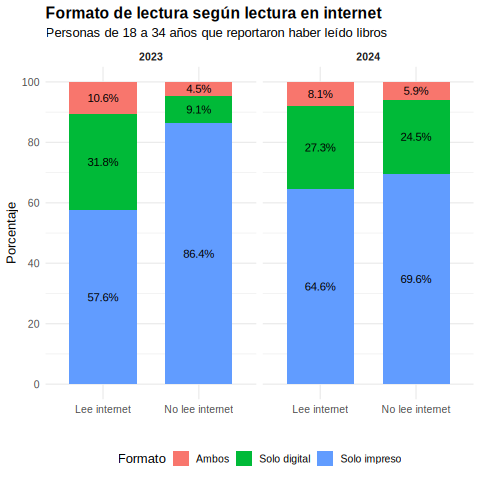

In [ ]:
%%R

# Hacemos una gráfica de barras apiladas para comparar visualmente los porcentajes de 2023 y 2024
ggplot(
  tabla_formato,
  aes(
    x = internet,
    y = porcentaje,
    fill = formato_libro
  )
) +
  geom_col(width = 0.7) + # Dibujamos las columnas
  geom_text(              # Ponemos los porcentajes adentro de las barras
    aes(label = paste0(round(porcentaje, 1), "%")),
    position = position_stack(vjust = 0.5),
    size = 4
  ) +
  facet_wrap(~anio) +     # Separamos una gráfica para 2023 y otra para 2024
  labs(
    title = "Formato de lectura según lectura en internet",
    subtitle = "Personas de 18 a 34 años que reportaron haber leído libros",
    x = "",
    y = "Porcentaje",
    fill = "Formato"
  ) +
  scale_y_continuous(
    limits = c(0,100),
    breaks = seq(0,100,20)
  ) +
  theme_minimal(base_size = 13) + # Usamos un diseño limpio y bonito
  theme(
    legend.position = "bottom",
    plot.title = element_text(face = "bold"),
    strip.text = element_text(face = "bold")
  )

In [ ]:
%%R

# Filtramos los datos únicamente para el año 2023
formato23 = formato %>%
  filter(anio == 2023)

# Creamos la tabla de contingencia de internet vs formato de libro para 2023
tabla23 = table(
  formato23$internet,
  formato23$formato_libro
)

tabla23

# Hacemos la prueba Chi-cuadrada para ver si están relacionados en 2023
prueba_formato23 = chisq.test(
  tabla23,
  correct = FALSE
)

prueba_formato23

# Vemos las frecuencias esperadas para confirmar que se cumple el supuesto de la prueba
prueba_formato23$expected

                 
                      Ambos Solo digital Solo impreso
  Lee internet    17.307692     49.15385    131.53846
  No lee internet  7.692308     21.84615     58.46154


In [ ]:
%%R

# Hacemos exactamente lo mismo pero ahora para el año 2024
formato24 = formato %>%
  filter(anio == 2024)

# Creamos la tabla de contingencia para 2024
tabla24 = table(
  formato24$internet,
  formato24$formato_libro
)

tabla24

# Aplicamos la prueba Chi-cuadrada para 2024
prueba_formato24 = chisq.test(
  tabla24,
  correct = FALSE
)

prueba_formato24

# Revisamos los valores esperados para 2024
prueba_formato24$expected

                 
                  Ambos Solo digital Solo impreso
  Lee internet    14.52        52.14       131.34
  No lee internet  7.48        26.86        67.66
